In [74]:
import trovolut as trv
import numpy as np 

def make_mats():
    import rdkit
    from rdkit import Chem
    from rdkit.Chem import AllChem
    dmds_smiles = "CSSC"

    # RDKit: SMILES -> mol
    mol = Chem.MolFromSmiles(dmds_smiles)
    mol = Chem.AddHs(mol)  # add hydrogens

    # embed 3D coordinates
    AllChem.EmbedMolecule(mol, AllChem.ETKDGv3())
    AllChem.UFFOptimizeMolecule(mol)

    # extract XYZ as multiline string in standard XYZ format:
    atoms = [atom.GetSymbol() for atom in mol.GetAtoms()]
    conf = mol.GetConformer()

    xyz_lines = []
    xyz_lines.append(str(len(atoms)))
    xyz_lines.append("dmds generated by RDKit")
    for i, sym in enumerate(atoms):
        pos = conf.GetAtomPosition(i)
        xyz_lines.append(f"{sym} {pos.x:.8f} {pos.y:.8f} {pos.z:.8f}")

    dmds_xyz = "\n".join(xyz_lines)

    H_elec = trv.qm.ElectronicHamiltonian.from_xyz(
        xyz_source=dmds_xyz,
        basis="sto-3g",
        charge=0,
        spin_mult=1,
        use_gpu4pyscf=False,
        freeze_core=True,
        n_core_keep=2,
        n_virt_keep=2,
    ).to_qubits()

    hamcoeffs = H_elec.terms()
    mats = [term['coef'] * term['matrix'] for term in hamcoeffs]
    return mats

matrices = make_mats()  
print("Hamiltonian terms:", len(matrices))
print("Size of hamiltonian matrices:", matrices[0].shape)

converged SCF energy = -864.654938657898


/Users/luismantilla/Desktop/UofT/NVIDIA/trovolut/.venv/lib/python3.13/site-packages/pyscf/lib/misc.py:1238: Warning: 
        Seeding the random number generator with a non-constant value
        inside Legate can lead to undefined behavior and/or errors when
        the program is executed with multiple ranks.
  random.seed()
<cupynumeric internals>:284: RuntimeWarning: cuPyNumeric has not implemented numpy.kron and is falling back to canonical NumPy. You may notice significantly decreased performance for this function call.

Set CUPYNUMERIC_FALLBACK_STACKTRACE=1 and re-run to include a full stack trace with this warning.


Hamiltonian terms: 365
Size of hamiltonian matrices: (256, 256)


In [75]:
matrices = make_mats()
norms = [np.linalg.norm(mat) for mat in matrices]
# print size of matrices, how many terms, and norms
print("Hamiltonian terms:", len(matrices))
print("Size of hamiltonian matrices:", matrices[0].shape)
print("Norms of Hamiltonian terms:", norms)

converged SCF energy = -864.654938665794
Hamiltonian terms: 263
Size of hamiltonian matrices: (256, 256)
Norms of Hamiltonian terms: [np.float64(371122.59396892344), np.float64(1208.411324554528), np.float64(5.530926911087043e-15), np.float64(5.530926911087043e-15), np.float64(1.7695706231061156e-11), np.float64(1.7695706231061156e-11), np.float64(1208.411324554528), np.float64(6.483159481870672e-15), np.float64(6.483159481870672e-15), np.float64(5.530926911087043e-15), np.float64(5.530926911087043e-15), np.float64(1.7695706231061156e-11), np.float64(1.7695706231061156e-11), np.float64(1203.8675006650842), np.float64(0.0002801786488891856), np.float64(0.0002801786488891856), np.float64(0.5778375418232918), np.float64(0.5778375418232918), np.float64(1203.8675006650842), np.float64(0.00028017864888918567), np.float64(0.00028017864888918567), np.float64(0.5778375418232918), np.float64(0.5778375418232918), np.float64(1366.0138680726968), np.float64(1.1129721092554583), np.float64(1.1129721

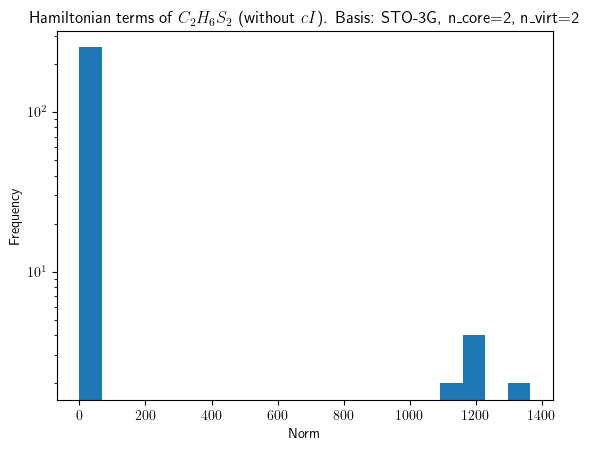

In [76]:
# histogram of norms
import matplotlib.pyplot as plt
# render in latex
plt.rcParams['text.usetex'] = True

plt.hist(norms[1:], bins=20)
plt.xlabel("Norm")
plt.ylabel("Frequency")
# logscale
# plt.xscale("log")
plt.yscale("log")
plt.title(rf'Hamiltonian terms of $C_2H_6S_2$ (without  $c I $). Basis: STO-3G, n_core=2, n_virt=2')
plt.show()


In [77]:
def sparsity(a: np.ndarray) -> float:
    """Fraction of elements that are exactly zero."""
    total = a.size
    # count all elements with value less than 1e-10 as zero
    # a = np.where(np.abs(a) < 1e-4, 0, a)
    nnz = np.count_nonzero(a)
    return 1.0 - nnz / total

def density(a: np.ndarray) -> float:
    """Fraction of elements that are nonzero."""
    return np.count_nonzero(a) / a.size

In [78]:
np.count_nonzero(matrices[1]), matrices[0].shape

(np.int64(256), (256, 256))

In [79]:
matrices[1]

array([[ 75.52570778+0.j,   0.        +0.j,   0.        +0.j, ...,
          0.        +0.j,   0.        +0.j,   0.        +0.j],
       [  0.        +0.j,  75.52570778+0.j,   0.        +0.j, ...,
          0.        +0.j,   0.        +0.j,   0.        +0.j],
       [  0.        +0.j,   0.        +0.j,  75.52570778+0.j, ...,
          0.        +0.j,   0.        +0.j,   0.        +0.j],
       ...,
       [  0.        +0.j,   0.        +0.j,   0.        +0.j, ...,
        -75.52570778+0.j,  -0.        +0.j,  -0.        +0.j],
       [  0.        +0.j,   0.        +0.j,   0.        +0.j, ...,
         -0.        +0.j, -75.52570778+0.j,  -0.        +0.j],
       [  0.        +0.j,   0.        +0.j,   0.        +0.j, ...,
         -0.        +0.j,  -0.        +0.j, -75.52570778+0.j]],
      shape=(256, 256))

In [80]:
num_elements = matrices[0].size
print("Number of elements in each matrix:", num_elements)

Number of elements in each matrix: 65536


In [81]:
mat_densities = [density(mat) for mat in matrices]
mat_densities

[np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),
 np.float64(0.00390625),


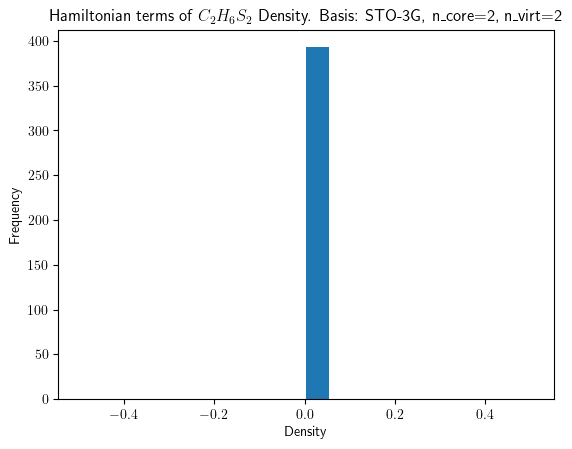

In [52]:
# histogram of norms
import matplotlib.pyplot as plt
# render in latex
plt.rcParams['text.usetex'] = True

plt.hist(mat_densities, bins=20)
plt.xlabel("Density")
plt.ylabel("Frequency")
plt.title(rf'Hamiltonian terms of $C_2H_6S_2$ Density. Basis: STO-3G, n_core=2, n_virt=2')
# lim from 0 to 1
# plt.xlim(0, 1)
plt.show()
